# Análise de fatores institucionais associados ao abandono escolar no Ensino Médio

**Grupo:** Brazilian Education Data  
**Curso:** Ciência de Dados — PUC Minas

## Objetivo do notebook

Este notebook organiza a análise em torno da **taxa oficial de abandono escolar do Ensino Médio em 2024**, obtida na tabela de Taxas de Rendimento Escolar do Inep. A base escolar de 2025 é utilizada para representar os atributos institucionais das escolas: infraestrutura, acessibilidade, conectividade, recursos humanos, localização, dependência administrativa e participação institucional.

A mudança metodológica principal é que **não será construído nem utilizado um índice próprio de vulnerabilidade**. Em vez disso, a modelagem supervisionada usa uma variável-alvo observada:

- **Sem abandono:** taxa de abandono no Ensino Médio igual a 0% em 2024;
- **Com abandono:** taxa de abandono no Ensino Médio maior que 0% em 2024.

## Limitação temporal importante

A variável-alvo é de **2024**, enquanto os atributos institucionais são de **2025**. Essa escolha ocorre porque, no momento da análise, os dados de rendimento/abandono de 2025 ainda não estavam disponíveis com a informação necessária por escola, enquanto a base escolar de 2025 apresentava maior completude para os atributos institucionais usados no projeto.

Portanto, os resultados devem ser interpretados como **exploratórios e associativos**, não como evidência causal direta.


## 1. Importações e configuração inicial

Nesta etapa são importadas as bibliotecas usadas para tratamento dos dados, visualização, pré-processamento e modelagem supervisionada.


In [1]:
# ─────────────────────────────────────────────────────────────────────────────
# 1. Bibliotecas
# ─────────────────────────────────────────────────────────────────────────────

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.inspection import permutation_importance

pd.set_option("display.max_columns", 120)
pd.set_option("display.max_rows", 120)

RANDOM_STATE = 42


## 2. Caminhos dos arquivos

Altere os caminhos abaixo conforme a pasta onde os arquivos estiverem salvos no seu computador.

Arquivos esperados:

1. `Tabela_Escola_2025.csv` — atributos institucionais das escolas;
2. `Tabela_Matricula_2025.csv` — matrículas no Ensino Médio regular;
3. `tx_rend_escolas_2024.xlsx` — taxas oficiais de rendimento escolar por escola, incluindo abandono.


In [2]:
# ─────────────────────────────────────────────────────────────────────────────
# 2. Caminhos dos arquivos
# ─────────────────────────────────────────────────────────────────────────────

CAMINHO_ESCOLA = "Tabela_Escola_2025.csv"
CAMINHO_MATRICULA = "Tabela_Matricula_2025.csv"
CAMINHO_RENDIMENTO_2024 = "tx_rend_escolas_2024.xlsx"

for caminho in [CAMINHO_ESCOLA, CAMINHO_MATRICULA, CAMINHO_RENDIMENTO_2024]:
    print(f"{caminho}: {'OK' if os.path.exists(caminho) else 'não encontrado'}")


Tabela_Escola_2025.csv: OK
Tabela_Matricula_2025.csv: OK
tx_rend_escolas_2024.xlsx: OK


## 3. Carregamento das bases de 2025

A base de escolas contém os atributos institucionais. A base de matrículas é usada para identificar e caracterizar escolas com matrículas no Ensino Médio regular diurno e/ou noturno.


In [3]:
# ─────────────────────────────────────────────────────────────────────────────
# 3. Leitura das bases de 2025
# ─────────────────────────────────────────────────────────────────────────────

escola_df = pd.read_csv(
    CAMINHO_ESCOLA,
    sep=";",
    encoding="latin1",
    low_memory=False,
)

matricula_df = pd.read_csv(
    CAMINHO_MATRICULA,
    sep=";",
    encoding="latin1",
    low_memory=False,
)

print("Base escola:", escola_df.shape)
print("Base matrícula:", matricula_df.shape)


Base escola: (214192, 302)
Base matrícula: (178766, 237)


## 4. Recorte do Ensino Médio regular e integração das bases

O recorte do estudo considera apenas escolas que ofertam **Ensino Médio regular tradicional**, identificado por `IN_COMUM_MEDIO_MEDIO == 1`.

A integração é feita por `CO_ENTIDADE`, código único da escola.


In [4]:
# ─────────────────────────────────────────────────────────────────────────────
# 4. Filtragem do Ensino Médio regular
# ─────────────────────────────────────────────────────────────────────────────

# Garante que a chave de integração tenha tipo numérico compatível nas duas bases.
escola_df["CO_ENTIDADE"] = pd.to_numeric(escola_df["CO_ENTIDADE"], errors="coerce").astype("Int64")
matricula_df["CO_ENTIDADE"] = pd.to_numeric(matricula_df["CO_ENTIDADE"], errors="coerce").astype("Int64")

# Mantém apenas escolas que ofertam Ensino Médio regular tradicional.
escola_medio_df = escola_df[escola_df["IN_COMUM_MEDIO_MEDIO"] == 1].copy()

print(f"Escolas com Ensino Médio regular: {len(escola_medio_df):,}".replace(",", "."))
print(f"Percentual da base original: {len(escola_medio_df) / len(escola_df) * 100:.2f}%")

# Seleciona variáveis de matrícula do Ensino Médio regular diurno e noturno.
cols_matricula = ["CO_ENTIDADE", "QT_MAT_MED_D", "QT_MAT_MED_N"]
matricula_medio_df = matricula_df[cols_matricula].copy()

# Converte matrículas para numérico e remove escolas sem matrícula nas duas variáveis.
for col in ["QT_MAT_MED_D", "QT_MAT_MED_N"]:
    matricula_medio_df[col] = pd.to_numeric(matricula_medio_df[col], errors="coerce").fillna(0)

matricula_medio_df = matricula_medio_df[
    (matricula_medio_df["QT_MAT_MED_D"] > 0) | (matricula_medio_df["QT_MAT_MED_N"] > 0)
].copy()

# Integra escolas e matrículas.
base_df = escola_medio_df.merge(
    matricula_medio_df,
    on="CO_ENTIDADE",
    how="inner",
)

print("Base integrada 2025:", base_df.shape)


Escolas com Ensino Médio regular: 26.822
Percentual da base original: 12.52%
Base integrada 2025: (26811, 304)


## 5. Seleção de variáveis institucionais e criação de variáveis derivadas

Nesta etapa são organizados os grupos de variáveis usados na análise:

- infraestrutura básica;
- infraestrutura pedagógica e tecnológica;
- ambiente escolar;
- acessibilidade;
- recursos humanos;
- participação institucional;
- localização e dependência administrativa.

Também são criadas variáveis derivadas de apoio profissional e razão aluno/profissional. Essas variáveis **não compõem um índice**; elas são atributos institucionais usados para descrição e modelagem.


In [5]:
# ─────────────────────────────────────────────────────────────────────────────
# 5. Dicionários de nomes e grupos de variáveis
# ─────────────────────────────────────────────────────────────────────────────

LOC_MAP = {1: "Urbana", 2: "Rural"}
DEP_MAP = {1: "Federal", 2: "Estadual", 3: "Municipal", 4: "Privada"}

NOMES = {
    # Infraestrutura básica
    "IN_AGUA_POTAVEL": "Água potável",
    "IN_ENERGIA_REDE_PUBLICA": "Energia da rede pública",
    "IN_ESGOTO_REDE_PUBLICA": "Esgoto pela rede pública",
    "IN_ESGOTO_INEXISTENTE": "Esgoto inexistente",
    "IN_BANHEIRO": "Banheiro",
    "IN_BANHEIRO_PNE": "Banheiro acessível",
    "IN_COZINHA": "Cozinha",
    "IN_REFEITORIO": "Refeitório",
    "IN_ALIMENTACAO": "Alimentação escolar",

    # Infraestrutura pedagógica e tecnológica
    "IN_BIBLIOTECA": "Biblioteca",
    "IN_SALA_LEITURA": "Sala de leitura",
    "IN_LABORATORIO_CIENCIAS": "Laboratório de ciências",
    "IN_LABORATORIO_INFORMATICA": "Laboratório de informática",
    "IN_COMPUTADOR": "Computador",
    "IN_INTERNET": "Internet",
    "IN_INTERNET_ALUNOS": "Internet para alunos",
    "IN_BANDA_LARGA": "Banda larga",
    "IN_EQUIP_MULTIMIDIA": "Equipamentos multimídia",

    # Ambiente escolar
    "IN_AREA_VERDE": "Área verde",
    "IN_PATIO_COBERTO": "Pátio coberto",
    "IN_QUADRA_ESPORTES": "Quadra esportiva",
    "IN_QUADRA_ESPORTES_COBERTA": "Quadra coberta",

    # Acessibilidade
    "IN_ACESSIBILIDADE_RAMPAS": "Rampas de acessibilidade",
    "IN_ACESSIBILIDADE_PISOS_TATEIS": "Pisos táteis",
    "IN_ACESSIBILIDADE_SINAL_VISUAL": "Sinalização visual acessível",
    "IN_ACESSIBILIDADE_INEXISTENTE": "Acessibilidade inexistente",
    "IN_SALA_ATENDIMENTO_ESPECIAL": "Sala de atendimento especializado",

    # Recursos humanos
    "QT_PROF_COORDENADOR": "Coordenador",
    "QT_PROF_PSICOLOGO": "Psicólogo",
    "QT_PROF_ASSIST_SOCIAL": "Assistente social",
    "QT_PROF_PEDAGOGIA": "Profissional de pedagogia",
    "QT_PROF_BIBLIOTECARIO": "Bibliotecário",
    "QT_PROF_GESTAO": "Gestão escolar",
    "QT_PROF_APOIO": "Profissionais de apoio",
    "QT_PROF_GESTAO_COORD": "Gestão e coordenação",
    "ALUNOS_POR_PROF_APOIO": "Alunos por profissional de apoio",
    "ALUNOS_POR_GESTAO_COORD": "Alunos por gestão/coordenação",
}

COLS_INFRA_BASICA = [
    "IN_AGUA_POTAVEL", "IN_ENERGIA_REDE_PUBLICA", "IN_ESGOTO_REDE_PUBLICA",
    "IN_ESGOTO_INEXISTENTE", "IN_BANHEIRO", "IN_BANHEIRO_PNE",
    "IN_COZINHA", "IN_REFEITORIO", "IN_ALIMENTACAO",
]

COLS_INFRA_PED_TEC = [
    "IN_BIBLIOTECA", "IN_SALA_LEITURA", "IN_LABORATORIO_CIENCIAS",
    "IN_LABORATORIO_INFORMATICA", "IN_COMPUTADOR", "IN_INTERNET",
    "IN_INTERNET_ALUNOS", "IN_BANDA_LARGA", "IN_EQUIP_MULTIMIDIA",
]

COLS_AMBIENTE = [
    "IN_AREA_VERDE", "IN_PATIO_COBERTO", "IN_QUADRA_ESPORTES", "IN_QUADRA_ESPORTES_COBERTA",
]

COLS_ACESSIBILIDADE = [
    "IN_ACESSIBILIDADE_RAMPAS", "IN_ACESSIBILIDADE_PISOS_TATEIS",
    "IN_ACESSIBILIDADE_SINAL_VISUAL", "IN_ACESSIBILIDADE_INEXISTENTE",
    "IN_SALA_ATENDIMENTO_ESPECIAL",
]

COLS_PARTICIPACAO = [
    "IN_ORGAO_CONSELHO_ESCOLAR", "IN_ORGAO_GREMIO_ESTUDANTIL", "IN_ORGAO_ASS_PAIS_MESTRES",
]

COLS_PROF = [
    "QT_PROF_COORDENADOR", "QT_PROF_PSICOLOGO", "QT_PROF_ASSIST_SOCIAL",
    "QT_PROF_PEDAGOGIA", "QT_PROF_BIBLIOTECARIO", "QT_PROF_GESTAO",
]

COLS_BINARIAS = [
    c for c in (COLS_INFRA_BASICA + COLS_INFRA_PED_TEC + COLS_AMBIENTE + COLS_ACESSIBILIDADE + COLS_PARTICIPACAO)
    if c in base_df.columns
]

COLS_PROF = [c for c in COLS_PROF if c in base_df.columns]


In [6]:
# ─────────────────────────────────────────────────────────────────────────────
# 5.1 Limpeza e variáveis derivadas
# ─────────────────────────────────────────────────────────────────────────────

# Em algumas variáveis do Censo, códigos como 88888 podem representar categoria especial/sem informação.
# Para quantidades de profissionais, esse valor não deve ser tratado como número real de pessoas.
base_df[COLS_PROF] = base_df[COLS_PROF].replace(88888, np.nan).fillna(0)

# Matrícula total no Ensino Médio regular.
base_df["QT_MAT_MED_TOTAL"] = base_df["QT_MAT_MED_D"] + base_df["QT_MAT_MED_N"]

# Proporção de matrículas no turno noturno.
base_df["PROP_MAT_NOTURNO"] = np.where(
    base_df["QT_MAT_MED_TOTAL"] > 0,
    base_df["QT_MAT_MED_N"] / base_df["QT_MAT_MED_TOTAL"],
    np.nan,
)

# Variáveis agregadas de profissionais.
base_df["QT_PROF_APOIO"] = (
    base_df.get("QT_PROF_PSICOLOGO", 0)
    + base_df.get("QT_PROF_ASSIST_SOCIAL", 0)
    + base_df.get("QT_PROF_PEDAGOGIA", 0)
    + base_df.get("QT_PROF_BIBLIOTECARIO", 0)
)

base_df["QT_PROF_GESTAO_COORD"] = (
    base_df.get("QT_PROF_GESTAO", 0)
    + base_df.get("QT_PROF_COORDENADOR", 0)
)

# Razões aluno/profissional.
# Quando não há profissional, a razão é indefinida; por isso usamos NaN na descrição.
# Para modelagem, esses NaNs serão tratados depois.
for col_prof in ["QT_PROF_APOIO", "QT_PROF_GESTAO_COORD"] + COLS_PROF:
    nome_razao = "ALUNOS_POR_" + col_prof.replace("QT_PROF_", "")
    base_df[nome_razao] = np.where(
        base_df[col_prof] > 0,
        base_df["QT_MAT_MED_TOTAL"] / base_df[col_prof],
        np.nan,
    )

# Recodificação para facilitar leitura em gráficos e tabelas.
base_df["LOCALIZACAO"] = base_df["TP_LOCALIZACAO"].map(LOC_MAP)
base_df["DEPENDENCIA"] = base_df["TP_DEPENDENCIA"].map(DEP_MAP)

print("Base após variáveis derivadas:", base_df.shape)


Base após variáveis derivadas: (26811, 318)


## 6. Análise exploratória dos atributos institucionais

A análise exploratória descreve as condições das escolas antes da modelagem. Para variáveis binárias, a média é interpretada como a proporção de escolas que possuem determinado recurso.


In [7]:
# ─────────────────────────────────────────────────────────────────────────────
# 6.1 Proporção de escolas com cada recurso binário
# ─────────────────────────────────────────────────────────────────────────────

tabela_binarias = (
    base_df[COLS_BINARIAS]
    .mean(numeric_only=True)
    .mul(100)
    .round(2)
    .rename(index=NOMES)
    .reset_index()
)

tabela_binarias.columns = ["Atributo", "Percentual de escolas (%)"]
display(tabela_binarias)


,Atributo,Percentual de escolas (%)
0,Água potável,98.56
1,Energia da rede pública,98.56
2,Esgoto pela rede pública,72.37
3,Esgoto inexistente,1.13
4,Banheiro,98.44
5,Banheiro acessível,75.85
6,Cozinha,91.68
7,Refeitório,61.14
8,Alimentação escolar,72.42
9,Biblioteca,67.91


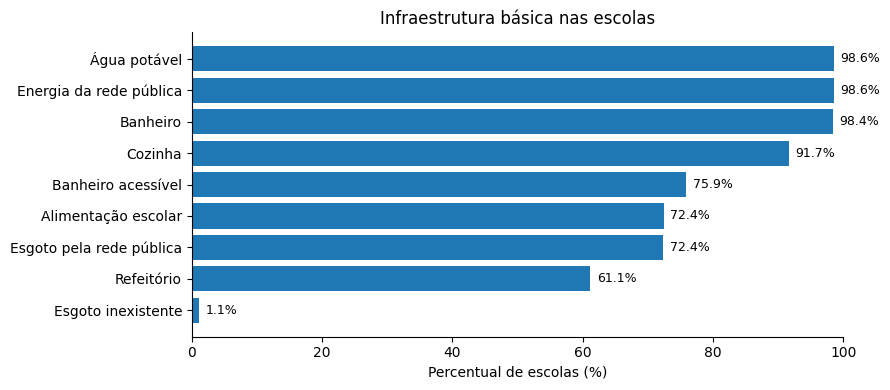

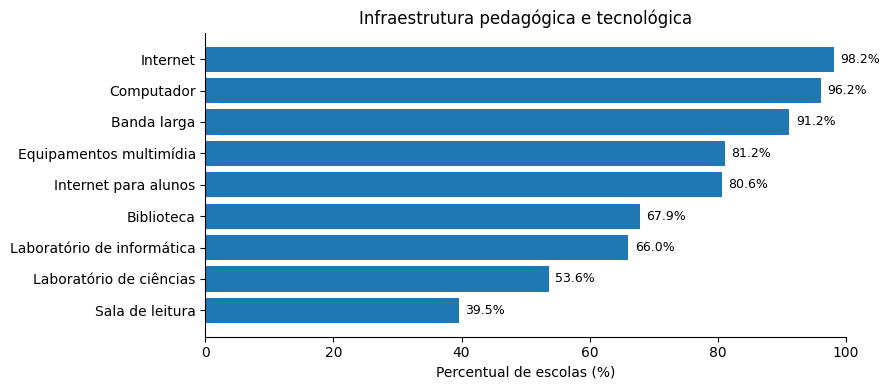

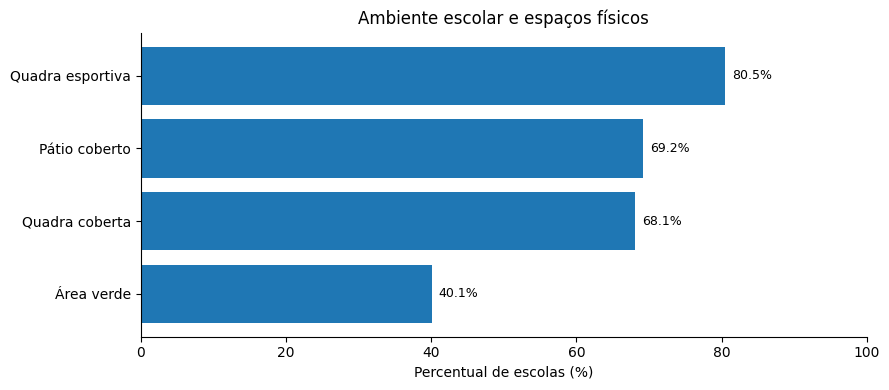

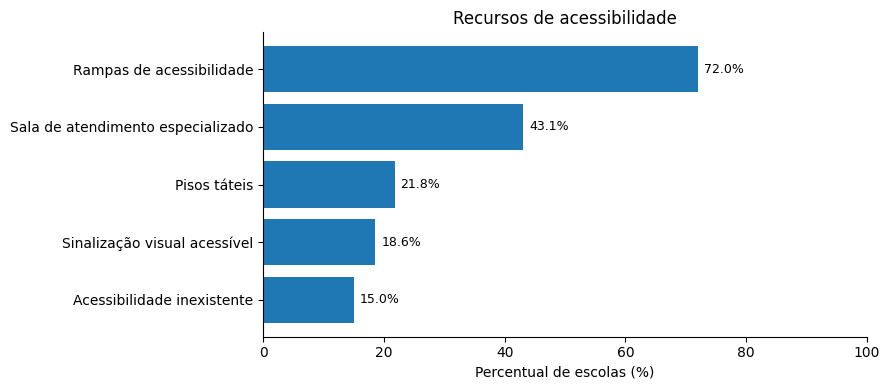

In [8]:
# ─────────────────────────────────────────────────────────────────────────────
# 6.2 Função auxiliar para gráficos de proporção
# ─────────────────────────────────────────────────────────────────────────────

def grafico_percentual_binario(df, colunas, titulo, nome_arquivo=None):
    # Gera gráfico de barras horizontais para variáveis binárias.
    colunas = [c for c in colunas if c in df.columns]
    valores = df[colunas].mean(numeric_only=True).mul(100).sort_values()
    rotulos = [NOMES.get(c, c) for c in valores.index]

    fig, ax = plt.subplots(figsize=(9, max(4, 0.35 * len(colunas))))
    ax.barh(rotulos, valores.values)
    ax.set_xlabel("Percentual de escolas (%)")
    ax.set_title(titulo)
    ax.set_xlim(0, 100)

    for i, v in enumerate(valores.values):
        ax.text(v + 1, i, f"{v:.1f}%", va="center", fontsize=9)

    ax.spines[["top", "right"]].set_visible(False)
    plt.tight_layout()

    if nome_arquivo:
        plt.savefig(nome_arquivo, dpi=300, bbox_inches="tight")

    plt.show()


grafico_percentual_binario(base_df, COLS_INFRA_BASICA, "Infraestrutura básica nas escolas", "infraestrutura_basica.png")
grafico_percentual_binario(base_df, COLS_INFRA_PED_TEC, "Infraestrutura pedagógica e tecnológica", "infraestrutura_pedagogica_tecnologica.png")
grafico_percentual_binario(base_df, COLS_AMBIENTE, "Ambiente escolar e espaços físicos", "ambiente_escolar.png")
grafico_percentual_binario(base_df, COLS_ACESSIBILIDADE, "Recursos de acessibilidade", "acessibilidade.png")


### 6.3 Comparação entre escolas urbanas e rurais

Esta análise verifica quais recursos apresentam maior diferença percentual entre escolas urbanas e rurais. A comparação é descritiva; não prova causalidade.


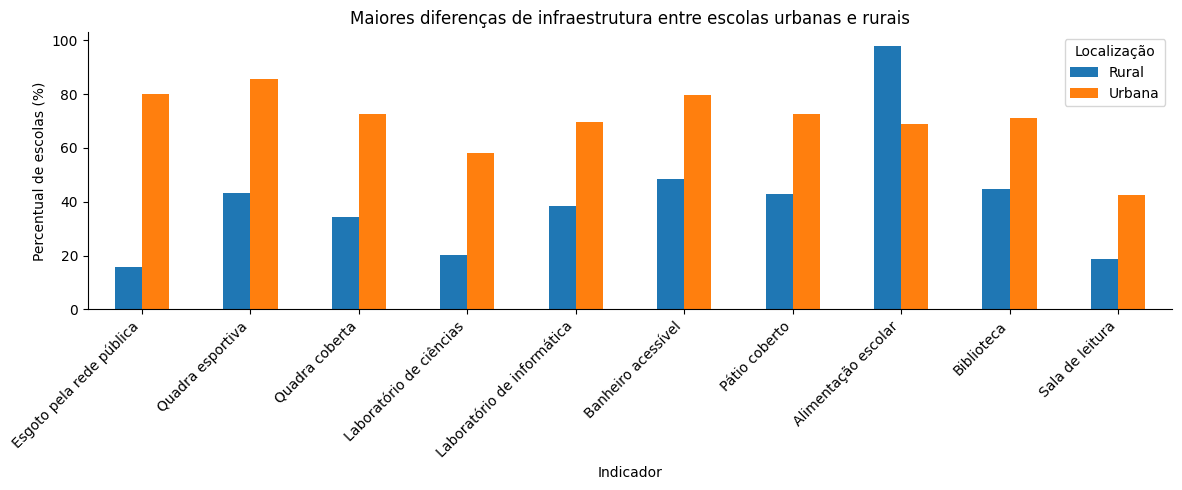

In [9]:
# ─────────────────────────────────────────────────────────────────────────────
# 6.3 Diferenças de infraestrutura por localização
# ─────────────────────────────────────────────────────────────────────────────

infra_loc = (
    base_df.groupby("LOCALIZACAO")[COLS_BINARIAS]
    .mean(numeric_only=True)
    .T
    .mul(100)
)

if {"Urbana", "Rural"}.issubset(set(infra_loc.columns)):
    diff_loc = (infra_loc["Urbana"] - infra_loc["Rural"]).abs().sort_values(ascending=False)
    top10_loc = diff_loc.head(10).index

    plot_df = infra_loc.loc[top10_loc].rename(index=NOMES)
    ax = plot_df.plot(kind="bar", figsize=(12, 5))
    ax.set_title("Maiores diferenças de infraestrutura entre escolas urbanas e rurais")
    ax.set_ylabel("Percentual de escolas (%)")
    ax.set_xlabel("Indicador")
    ax.legend(title="Localização")
    ax.spines[["top", "right"]].set_visible(False)
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.savefig("diferencas_urbano_rural.png", dpi=300, bbox_inches="tight")
    plt.show()
else:
    print("Não há escolas urbanas e rurais suficientes para comparar.")


### 6.4 Recursos humanos

A primeira análise verifica a presença de ao menos um profissional em cada categoria. A segunda observa a razão de alunos por profissional apenas nas escolas que possuem aquele profissional.


,Profissional,% com profissional,% sem profissional
3,Profissional de pedagogia,79.88,20.12
5,Gestão escolar,74.61,25.39
4,Bibliotecário,50.88,49.12
0,Coordenador,47.89,52.11
1,Psicólogo,25.12,74.88
2,Assistente social,9.33,90.67


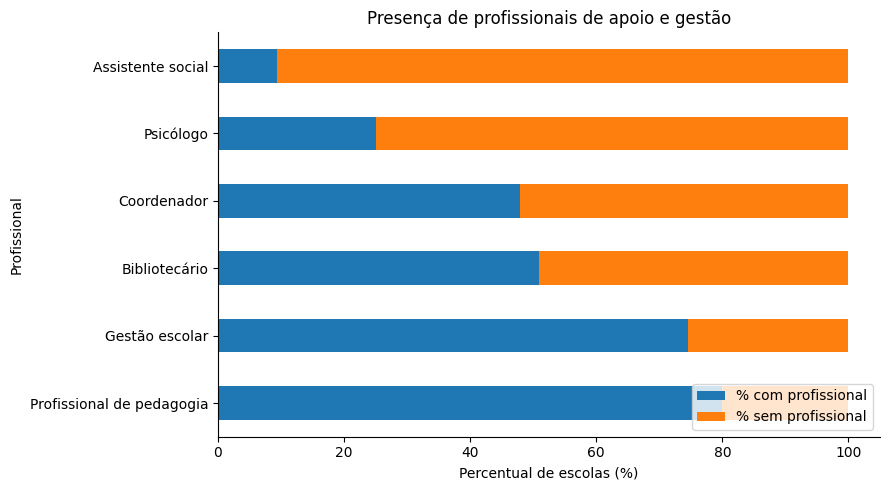

In [10]:
# ─────────────────────────────────────────────────────────────────────────────
# 6.4 Presença de profissionais
# ─────────────────────────────────────────────────────────────────────────────

tabela_prof = []

for col in COLS_PROF:
    tabela_prof.append({
        "Profissional": NOMES.get(col, col),
        "% com profissional": round((base_df[col] > 0).mean() * 100, 2),
        "% sem profissional": round((base_df[col] == 0).mean() * 100, 2),
    })

tabela_prof = pd.DataFrame(tabela_prof).sort_values("% com profissional", ascending=False)
display(tabela_prof)

ax = tabela_prof.set_index("Profissional")[["% com profissional", "% sem profissional"]].plot(
    kind="barh",
    stacked=True,
    figsize=(9, 5),
)
ax.set_title("Presença de profissionais de apoio e gestão")
ax.set_xlabel("Percentual de escolas (%)")
ax.legend(loc="lower right")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("presenca_profissionais.png", dpi=300, bbox_inches="tight")
plt.show()


/var/folders/j9/4fp7md656bs8bn5068_g67w80000gn/T/ipykernel_79695/82326548.py:17: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(razoes_prof, labels=labels_prof, showfliers=False)


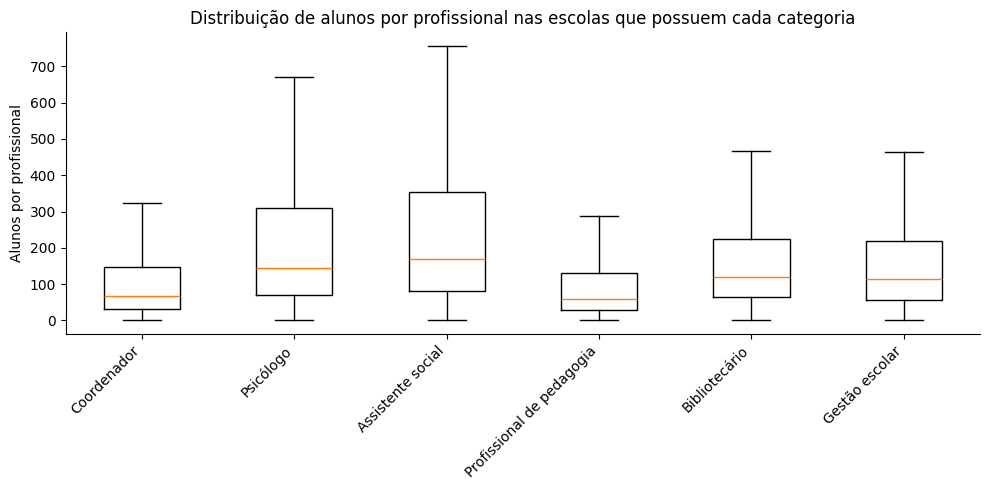

In [11]:
# ─────────────────────────────────────────────────────────────────────────────
# 6.5 Alunos por profissional nas escolas com cada categoria
# ─────────────────────────────────────────────────────────────────────────────

razoes_prof = []
labels_prof = []

for col in COLS_PROF:
    nome_razao = "ALUNOS_POR_" + col.replace("QT_PROF_", "")
    if nome_razao in base_df.columns:
        s = base_df.loc[base_df[col] > 0, nome_razao].dropna()
        if len(s) > 0:
            razoes_prof.append(s)
            labels_prof.append(NOMES.get(col, col))

fig, ax = plt.subplots(figsize=(10, 5))
ax.boxplot(razoes_prof, labels=labels_prof, showfliers=False)
ax.set_title("Distribuição de alunos por profissional nas escolas que possuem cada categoria")
ax.set_ylabel("Alunos por profissional")
plt.xticks(rotation=45, ha="right")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("alunos_por_profissional.png", dpi=300, bbox_inches="tight")
plt.show()


### 6.6 Participação institucional

As variáveis de participação indicam a presença de conselho escolar, grêmio estudantil e associação de pais e mestres.


,Indicador,Percentual de escolas (%)
0,IN_ORGAO_CONSELHO_ESCOLAR,73.74
1,IN_ORGAO_GREMIO_ESTUDANTIL,44.04
2,IN_ORGAO_ASS_PAIS_MESTRES,31.84


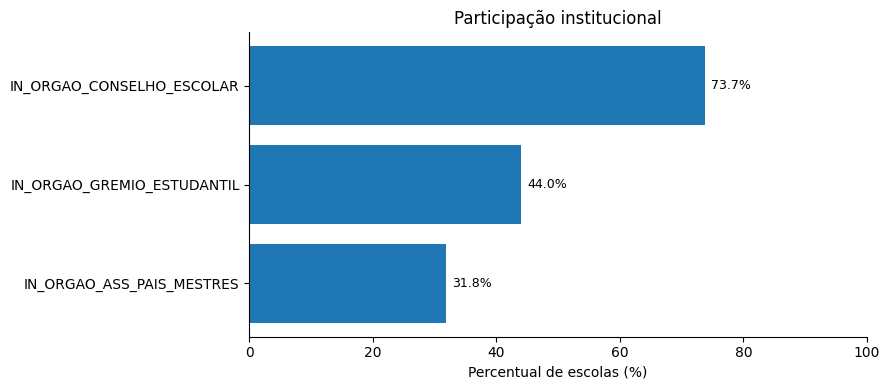

In [12]:
# ─────────────────────────────────────────────────────────────────────────────
# 6.6 Participação institucional
# ─────────────────────────────────────────────────────────────────────────────

cols_part = [c for c in COLS_PARTICIPACAO if c in base_df.columns]

if cols_part:
    tabela_part = (
        base_df[cols_part]
        .mean(numeric_only=True)
        .mul(100)
        .round(2)
        .rename(index=NOMES)
        .reset_index()
    )
    tabela_part.columns = ["Indicador", "Percentual de escolas (%)"]
    display(tabela_part)

    grafico_percentual_binario(base_df, cols_part, "Participação institucional", "participacao_institucional.png")
else:
    print("As variáveis de participação institucional não foram encontradas na base.")


### 6.7 Matriz de correlação exploratória

A matriz de correlação é usada apenas como análise descritiva para observar associações lineares entre variáveis numéricas e binárias. Correlação não implica causalidade.


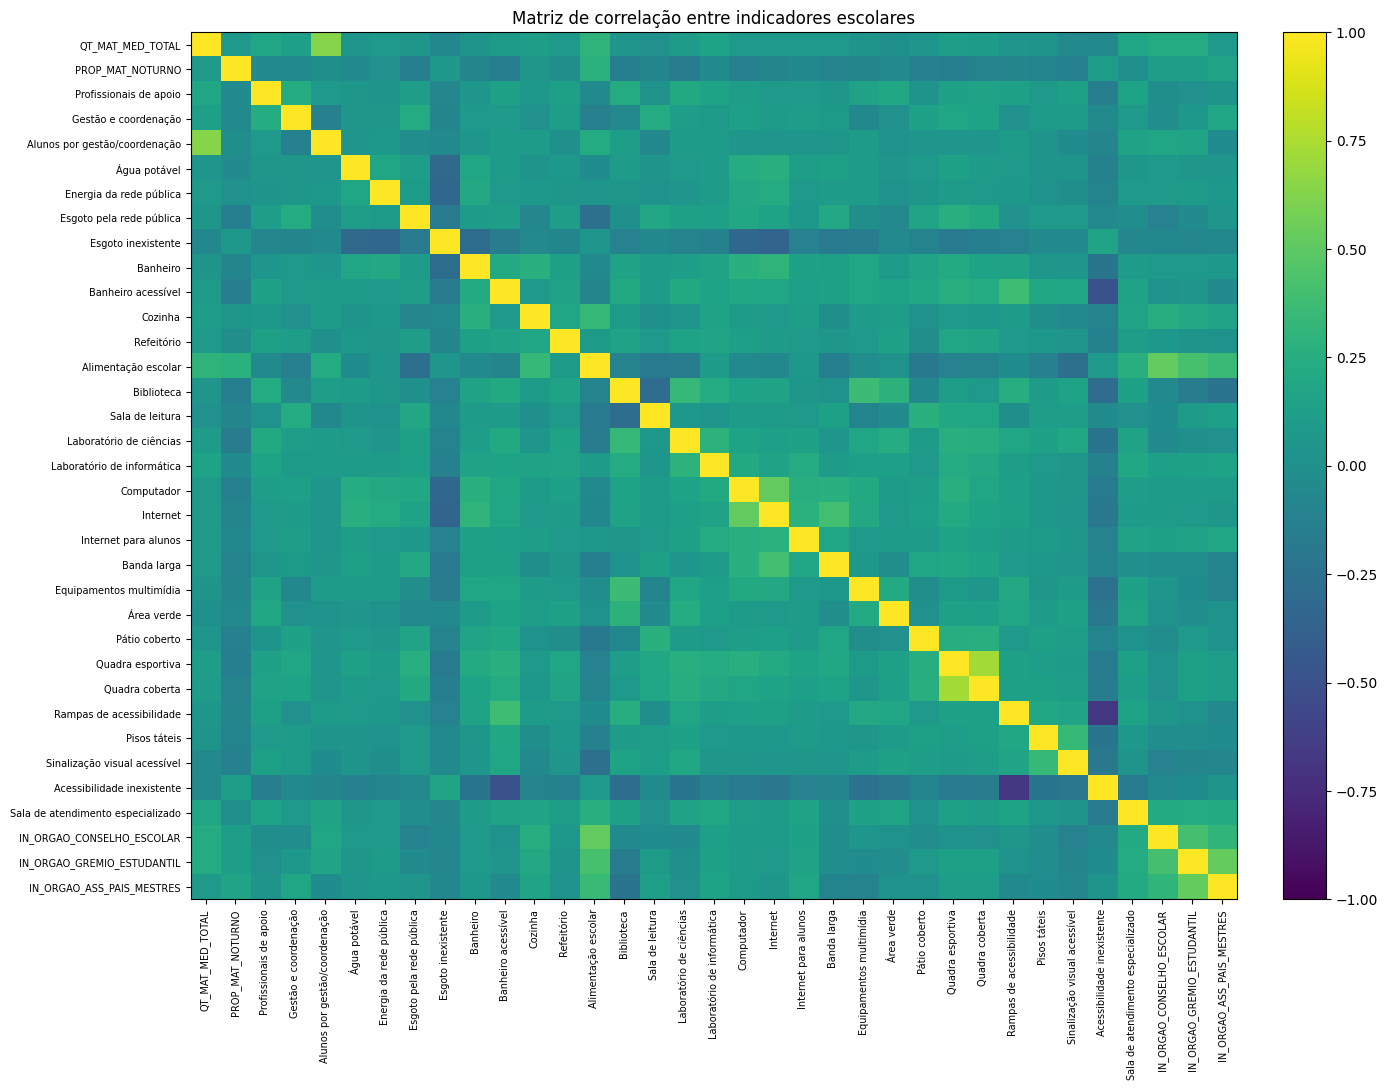

In [13]:
# ─────────────────────────────────────────────────────────────────────────────
# 6.7 Matriz de correlação
# ─────────────────────────────────────────────────────────────────────────────

cols_corr = [
    "QT_MAT_MED_TOTAL", "PROP_MAT_NOTURNO",
    "QT_PROF_APOIO", "QT_PROF_GESTAO_COORD",
    "ALUNOS_POR_PROF_APOIO", "ALUNOS_POR_GESTAO_COORD",
] + COLS_BINARIAS

cols_corr = [c for c in cols_corr if c in base_df.columns]

corr = base_df[cols_corr].replace([np.inf, -np.inf], np.nan).fillna(0).corr()

fig, ax = plt.subplots(figsize=(14, 11))
im = ax.imshow(corr, aspect="auto", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr.columns)))
ax.set_yticks(range(len(corr.columns)))
ax.set_xticklabels([NOMES.get(c, c) for c in corr.columns], rotation=90, fontsize=7)
ax.set_yticklabels([NOMES.get(c, c) for c in corr.columns], fontsize=7)
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
ax.set_title("Matriz de correlação entre indicadores escolares")
plt.tight_layout()
plt.savefig("matriz_correlacao.png", dpi=300, bbox_inches="tight")
plt.show()
